In [ ]:
from pathlib import Path
import subprocess
import sys
from google.colab import drive

DRIVE = Path('/content/drive')
drive.mount('/content/drive')

ROOT = DRIVE / "MyDrive" / "doctorado/materias/ml_geofluidos_inv/tp_final/codigos_eval"
assert ROOT.exists()
PACKAGE_DIR = ROOT / 'python_packages'
PACKAGE_DIR.mkdir(exist_ok=True)

sys.path.insert(0, str(PACKAGE_DIR))
print(PACKAGE_DIR.resolve())


if not (PACKAGE_DIR / 'cartopy').exists():
    subprocess.check_call([
        sys.executable, '-m', 'pip', 'install',
        '--target', str(PACKAGE_DIR), 'cartopy'
    ])


import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np
import pandas as pd
import string
import gc

sys.path.insert(0, str(ROOT / "src"))

from statistical_downscaling.evaluation.metrics.univariate.probabilistic import (
    spread_skill, crpss, crps_ensemble, climatological_reference
)


# variables globales

DATA_ROOT = ROOT / "data"
PREDS_ROOT = ROOT/ "outputs" / "aa_geoph_fluids"

VAR_DS = "precip"

print("PREDS_ROOT:", PREDS_ROOT.resolve())
print("DATA_ROOT:", DATA_ROOT.resolve())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/.shortcut-targets-by-id/1WkHyL_6hJDy8RansGc0sPwwdfLfvykxM/doctorado/materias/ml_geofluidos_inv/tp_final/codigos_eval/python_packages
PREDS_ROOT: /content/drive/.shortcut-targets-by-id/1WkHyL_6hJDy8RansGc0sPwwdfLfvykxM/doctorado/materias/ml_geofluidos_inv/tp_final/codigos_eval/outputs/aa_geoph_fluids
DATA_ROOT: /content/drive/.shortcut-targets-by-id/1WkHyL_6hJDy8RansGc0sPwwdfLfvykxM/doctorado/materias/ml_geofluidos_inv/tp_final/codigos_eval/data


In [ ]:
models = ["BerGamma", "DDPM", "FlowMatch"]

preds_models = {
    m: xr.open_dataset(list((PREDS_ROOT / m).glob("./*.nc") )[0])
    for m in models
}

ds_y_test = xr.open_dataset(DATA_ROOT / "predictands" / f"pr_SESA_ERA5.nc").sel(
    time=preds_models[models[0]].time.values
)


                         ERA5   BerGamma       DDPM  FlowMatch
threshold [mm/day]                                            
1                  0.32385856 0.32881996 0.39623000 0.30489380
5                  0.17443463 0.17516629 0.20344029 0.16438639
10                 0.10785575 0.10569980 0.12558767 0.09980465
20                 0.04635495 0.04548380 0.05474213 0.04231465
50                 0.00567510 0.00555028 0.00638383 0.00498443
100                0.00030796 0.00027110 0.00029366 0.00025659
150                0.00002525 0.00001768 0.00002135 0.00002493
200                0.00000262 0.00000141 0.00000279 0.00000352
250                0.00000039 0.00000011 0.00000058 0.00000077
300                0.00000006 0.00000001 0.00000012 0.00000019
400                0.00000000 0.00000000 0.00000000 0.00000001


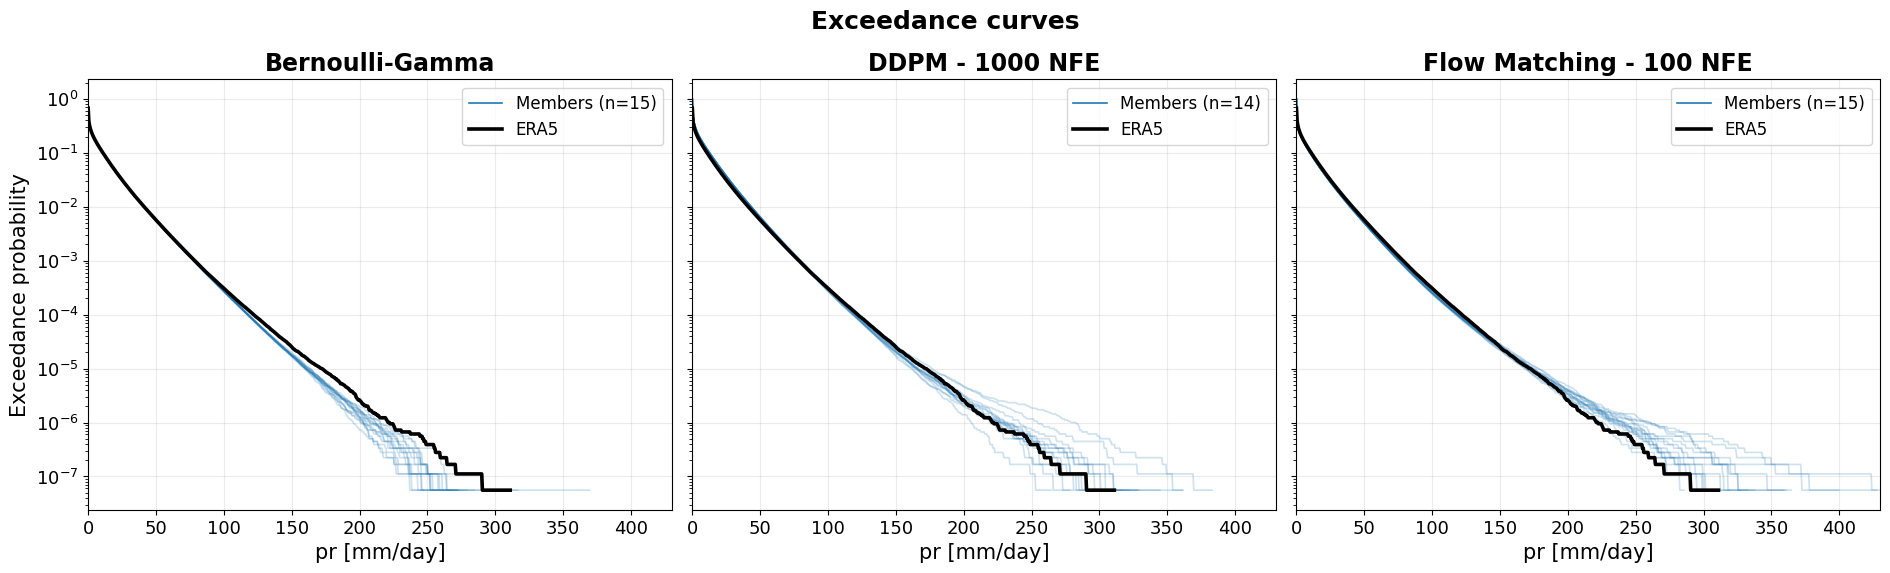

In [ ]:
thresholds = np.array([1, 5, 10, 20, 50, 100, 150, 200, 250, 300, 400])
u_grid = np.arange(0, 430.5, 0.5)


def exc_curve(x, u):
    x = np.asarray(x).ravel()
    x = np.sort(x[~np.isnan(x)])
    n_gt = x.size - np.searchsorted(x, u, side="right")
    return n_gt / x.size


def exc_by_member(da, u):
    return np.stack([
        exc_curve(da.isel(member=k).values, u)
        for k in range(da.sizes["member"])
    ])


exc_obs = exc_curve(ds_y_test[VAR_DS].values, u_grid)

exc_members = {
    m: exc_by_member(preds_models[m][VAR_DS], u_grid)
    for m in models
}


tabla = pd.DataFrame(
    {"ERA5": exc_curve(ds_y_test[VAR_DS].values, thresholds)}
    | {m: exc_curve(preds_models[m][VAR_DS].values, thresholds) for m in models},
    index=pd.Index(thresholds, name="threshold [mm/day]"),
)

with pd.option_context("display.float_format", "{:.8f}".format):
    print(tabla)

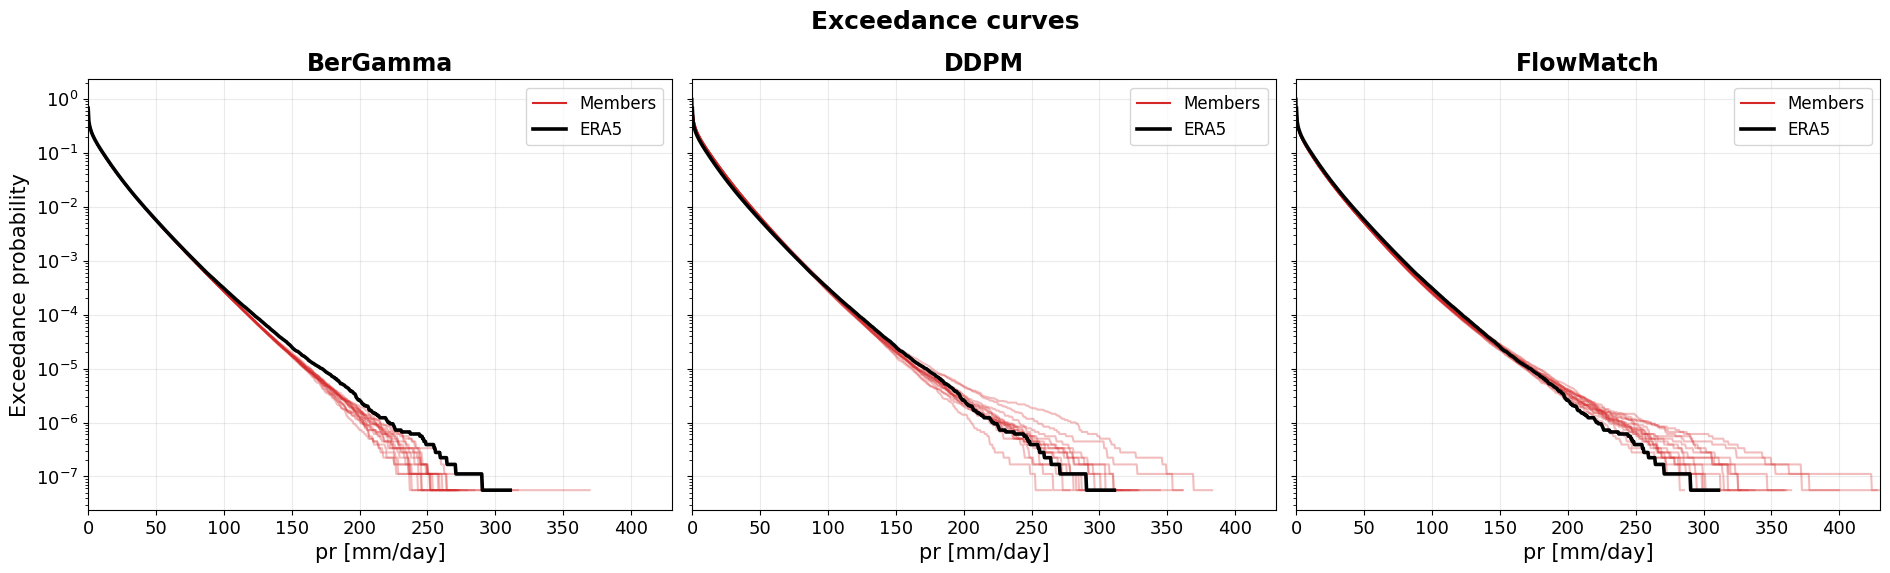

In [14]:
FIGSIZE = (19, 5.8)

SUPTITLE_SIZE = 18
TITLE_SIZE = 17
LABEL_SIZE = 15
TICK_SIZE = 13
LEGEND_SIZE = 12

OBS_LINEWIDTH = 2.6
MEMBER_LINEWIDTH = 1.5
MEMBER_ALPHA = 0.3

XMIN, XMAX = 0, 430

TITLES = {
    "BerGamma": "BerGamma",
    "DDPM": "DDPM",
    "FlowMatch": "FlowMatch",
}

MEMBER_COLOR = "tab:red"
OBS_COLOR = "black"

obs_plot = np.where(exc_obs > 0, exc_obs, np.nan)

fig, axes = plt.subplots(1, len(models), figsize=FIGSIZE, sharey=True)
axes = np.atleast_1d(axes)

for ax, m in zip(axes, models):

    exc = np.where(exc_members[m] > 0, exc_members[m], np.nan)

    ax.plot(
        u_grid,
        exc.T,
        color=MEMBER_COLOR,
        alpha=MEMBER_ALPHA,
        linewidth=MEMBER_LINEWIDTH,
    )
    ax.plot([], [], color=MEMBER_COLOR, linewidth=MEMBER_LINEWIDTH,
            label=f"Members")

    ax.plot(
        u_grid,
        obs_plot,
        color=OBS_COLOR,
        linewidth=OBS_LINEWIDTH,
        label="ERA5",
    )

    ax.set_yscale("log")
    ax.set_xlim(XMIN, XMAX)
    ax.set_title(TITLES.get(m, m), fontsize=TITLE_SIZE, fontweight="bold")
    ax.set_xlabel("pr [mm/day]", fontsize=LABEL_SIZE)
    ax.grid(alpha=0.25)
    ax.legend(fontsize=LEGEND_SIZE)
    ax.tick_params(labelsize=TICK_SIZE)

axes[0].set_ylabel("Exceedance probability", fontsize=LABEL_SIZE)

fig.suptitle("Exceedance curves", fontsize=SUPTITLE_SIZE, fontweight="bold")

plt.tight_layout()
plt.show()